# gras — a tour of the Python bindings

`gras` searches neural architectures while they train: a population of candidate
nets shares one seeded stream, gets scored every step, and the weak ones are
culled as soon as they fall behind. Nothing below is a simulation of that —
every number comes out of the real engine, and every artifact it writes stays
on disk for you to diff later.

**v1 surface, in full:** `RaceConfig` → `RaceEngine` with a whole-race `run()`,
plus `Topology` as an opaque JSON handle. That is deliberately small: the
artifacts are the interface, and the artifacts are the same ones the Rust side
writes.

## Before the first cell

`gras._core` is a compiled Rust module linked against libtorch, so it has to be
built in the same environment the crate uses. From the repository root:

```bash
source env_setup.sh                          # libtorch → LD_LIBRARY_PATH
uv pip install maturin --python .venv/bin/python3
VIRTUAL_ENV="$PWD/.venv" .venv/bin/maturin develop --manifest-path gras-py/Cargo.toml

# CUDA instead — then set CUDA = True in the first code cell:
source env_setup.sh cuda
VIRTUAL_ENV="$PWD/.venv" .venv/bin/maturin develop --features cuda --manifest-path gras-py/Cargo.toml
```

That compiles `gras-py` and drops `_core.cpython-*.so` into `python/gras/`.
`import gras` then finds libtorch on its own: it preloads
`$LIBTORCH_PATH/lib/libtorch_cpu.so`, or fdl's shared copy under
`~/.flodl/libtorch/precompiled/{cpu,cuda}/lib`, so a Jupyter kernel started
outside the `env_setup.sh` shell still imports. If neither path exists, install
libtorch the way that script does.

The device is chosen at build time (the crate's `cuda` feature), so the `CUDA`
flag in the first code cell does not switch backends: it asserts that the
extension you built is the one the rest of the notebook assumes.

## What we'll cover

1. finding the checkout and loading the module,
2. the knobs on `RaceConfig` (before/after),
3. what the engine says while it runs, and how to quiet it,
4. the smallest race that still produces a real fitness stream,
5. `history.csv` — long view, wide view, and four charts,
6. deterministic replay: same seed in, same stream out (and why the header
   isn't the thing you compare),
7. `risk_aversion` as a before/after: same seed, different cull decisions,
8. reading one candidate's topology as JSON,
9. bringing your own data (CSV or the native binary),
10. what v1 deliberately does not do.

In [1]:
# The bash recipe above, for when you would rather not leave the notebook.
# `None` does nothing; set it to "cpu" or "cuda" to rebuild in place. This cell is
# first so a rebuild lands before `import gras`; if the module is already loaded
# (you have run cells in this kernel), restart the kernel afterwards.
REBUILD = None

if REBUILD is not None:
    import subprocess
    import sys
    from pathlib import Path

    root = next(
        (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "gras-py" / "Cargo.toml").is_file()),
        None,
    )
    if root is None:
        raise RuntimeError("run this notebook from inside the gras checkout")
    if "gras" in sys.modules:
        print("gras is already imported in this kernel: restart it after this build.")

    backend = "" if REBUILD == "cpu" else " cuda"
    features = "" if REBUILD == "cpu" else " --features cuda"
    recipe = "\n".join(
        [
            "set -eo pipefail",
            f"source env_setup.sh{backend}",
            f'VIRTUAL_ENV="$PWD/.venv" .venv/bin/maturin develop'
            f'{features} --manifest-path gras-py/Cargo.toml',
        ]
    )
    build = subprocess.Popen(
        ["bash", "-lc", recipe],
        cwd=root,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    for line in build.stdout:
        print(line, end="")
    if build.wait() != 0:
        raise RuntimeError(f"maturin develop failed for {REBUILD}")
    print(f"\nrebuilt for {REBUILD}; restart the kernel, then run from the top.")

In [2]:
from __future__ import annotations

import hashlib
import json
import subprocess
import sys
import tempfile
from pathlib import Path

import gras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gras import RaceConfig, RaceEngine, Topology

# The backend is baked into the extension at BUILD time (the crate's `cuda`
# feature); this flag only asserts that the build matches. Build with
# `--features cuda` as shown at the top, flip this to True, run everything again.
CUDA = False

# The race's shape, named once — no magic numbers drifting between cells.
POP = 8
ELITES = 1
STEPS = 8
SEED = 42

# The tiny race the replay check uses: same shape, cheaper to repeat.
TINY_POP = 4
TINY_STEPS = 3

# risk_aversion (λ): 0 ranks on the plain window mean, 2 charges a net for its
# own spread. Same seed in the A/B, so only the ranking may differ.
LAMBDA_OFF = 0.0
LAMBDA_STRICT = 2.0

# ...and refuse to run against a build that disagrees with the flag, so a CPU
# wheel never gets mistaken for a CUDA one.
if gras.built_with_cuda != CUDA:
    shell = "source env_setup.sh" + (" cuda" if CUDA else "")
    features = " --features cuda" if CUDA else ""
    raise RuntimeError(
        f"CUDA={CUDA}, but the installed extension was built with "
        f"cuda={gras.built_with_cuda}. Rebuild it to match:\n"
        f"  {shell} && VIRTUAL_ENV=\"$PWD/.venv\" .venv/bin/maturin develop"
        f"{features} --manifest-path gras-py/Cargo.toml"
    )


def find_repo_root(start: Path | None = None) -> Path:
    """Walk up from the cwd until we find the checkout (Cargo.toml + data/)."""
    here = (start or Path.cwd()).resolve()
    for candidate in (here, *here.parents):
        if (candidate / "Cargo.toml").is_file() and (candidate / "data" / "blobs").is_dir():
            return candidate
    raise RuntimeError("run this notebook from inside the gras checkout")


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data" / "blobs"

print(f"gras     {gras.__version__} from {Path(gras.__file__).parent}")
print(f"backend  {'cuda' if gras.built_with_cuda else 'cpu'} (CUDA flag: {CUDA})")
print(f"checkout {REPO_ROOT}")
print(f"dataset  {DATA_DIR.relative_to(REPO_ROOT)} (256 rows, 2 inputs → 3 classes)")

gras     0.1.0 from /home/maulb/gras/python/gras
backend  cpu (CUDA flag: False)
checkout /home/maulb/gras
dataset  data/blobs (256 rows, 2 inputs → 3 classes)


## 1. The knobs you actually turn

`RaceConfig` is a plain Python object with live attributes — no builder, no
`rebuild()`. A field you leave out keeps its default, which is the crate's
`RaceConfig::defaults()` with two deliberate exceptions: `risk_aversion` is
`0.0` (rank on the plain mean, no charge for spread unless you ask) and
`elite_previous_load` is `False` (all-random founders). The probation timers are
the one family that is NOT zeroed: `0` there would remove a protection rather than
switch off an effect on the ranking, so they inherit the crate's `5`. Every field
is recorded
in the run's `engine.json`, so any run can be described by the config that
produced it.

| field | default | what it does |
|---|---|---|
| `pop_size` | `5` | live networks in the race (elite seats are inside this count) |
| `elite_count` | `1` | how many top-ranked nets are protected from culling |
| `max_steps` | `None` | step budget; `None` means "run until another stop fires" |
| `smoothing_window` | `10` | how many recent readings the ranker averages |
| `risk_aversion` | `0.0` | λ: rank on `mean − λ·σ`, charging a net for its own spread; `0.0` is the plain mean (the crate's FIT default is `1.0`) |
| `train_merit` | `0.0` | Ω: how much of each clock the train/eval lottery decides; `0.0` = off, every net runs |
| `crossover_prob` | `0.5` | chance a crossover roll fires (a spent roll inserts nothing) |
| `mutate_prob` | `0.5` | chance a mutation roll fires and inserts a random immigrant |
| `crossover_ops_pool` | `[]` | mixing methods a crossover may draw: `one_point`, `uniform`; empty = both |
| `activation_pool` | `[]` | activations the search may draw; empty = all |
| `hidden_nodes_pool` | `None` | `(min, max)` hidden NODES per net; `None` = the crate's `2..=5` |
| `hidden_inputs_pool` | `None` | wires INTO each hidden node, `(min, max)`; `None` = `2..=5` |
| `hidden_outputs_pool` | `None` | wires OUT of each hidden node, `(min, max)`; `None` = `2..=5` |
| `dropout_prob` | `0.0` | dropout baked into each net at build (train path only) |
| `checkpoint_every` | `10` | steps between checkpoints (era rotation + CSV flush); `0` = no tick |
| `elite_checkpoint_weights` | `True` | include the top nets' weights in each checkpoint file |
| `mutation_probation_steps` | `5` | clocks a fresh immigrant is immune to culling |
| `crossover_probation_steps` | `5` | clocks a crossover child is immune to culling |
| `elite_join_probation_steps` | `5` | clocks a net must train before it may hold an elite seat |
| `elite_crown_lifetime_steps` | `5` | clocks a net may sit on the frozen crown before it ages out |
| `elite_previous_load` | `False` | inherit ranked elites from the newest compatible run in `results/` |
| `log_level` | `"summ"` | reporting shape: `summ`, `minimal`, `none`, `debug`, `trace` |

In [3]:
# BEFORE: every default, nothing to think about yet.
print("before:", RaceConfig())

# AFTER: the same object, with the four knobs this tour cares about set.
cfg = RaceConfig(pop_size=POP, elite_count=ELITES, max_steps=STEPS)
print("after :", cfg)

# Fields stay live after construction — mutate now, no rebuild step.
cfg.risk_aversion = LAMBDA_OFF
cfg.elite_previous_load = False  # never inherit results/ from the cwd
cfg.log_level = "none"  # §2 shows what this mutes; the rest of the tour is quiet
print("tuned :", cfg)

before: RaceConfig(pop_size=8, elite_count=1, max_steps=None, smoothing_window=10, risk_aversion=0, elite_previous_load=false, log_level="summ")
after : RaceConfig(pop_size=8, elite_count=1, max_steps=Some(8), smoothing_window=10, risk_aversion=0, elite_previous_load=false, log_level="summ")
tuned : RaceConfig(pop_size=8, elite_count=1, max_steps=Some(8), smoothing_window=10, risk_aversion=0, elite_previous_load=false, log_level="none")


## 2. Listen to a race

The engine is talkative by design. Like every Rust example, the bindings
install the engine's console sink on the **first** `RaceEngine` in the process,
at the level from `RaceConfig.log_level` — `summ` by default. You get the run
header, one compact line per step, then the stop block; `minimal` swaps that
line for a vitals table, and `none` silences the run outright.

`summ` is the same vocabulary as the examples' `--log-level`, so the two sides
read alike, and `RUST_LOG` is deliberately ignored — the level you ask for is
the level you get.

**One notebook wrinkle.** Those lines are written by Rust straight to the
process's stdout, one level below Jupyter's per-cell capture: in a notebook
they land in the terminal running the kernel, not in the cell. So the next cell
runs the same race in a child interpreter and relays what it printed — real
output, not a mock-up. It is the same interpreter and the same built extension
(`gras._core`); only the capture is indirect, which is why the next cell
shows one card verbatim instead of restating its table.

In [4]:
def log_demo(level: str) -> str:
    """The tiny race, as a standalone script for a child interpreter."""
    return f'''\
import tempfile
from pathlib import Path
from gras import RaceConfig, RaceEngine

run_dir = Path(tempfile.mkdtemp(prefix="gras-log-demo-"))
RaceEngine(
    Path("data/blobs"),
    RaceConfig(pop_size=2, elite_count=1, max_steps=1, log_level="{level}"),
    seed=42,
    run_dir=run_dir,
).run()
'''


def engine_output(level: str) -> list[str]:
    """Run the demo race in a child interpreter; return the lines it printed."""
    finished = subprocess.run(
        [sys.executable, "-c", log_demo(level)],
        cwd=REPO_ROOT,
        text=True,
        capture_output=True,
    )
    if finished.returncode != 0:
        raise RuntimeError(finished.stderr.strip() or f"log demo exited {finished.returncode}")
    return finished.stdout.splitlines()


loud = engine_output("summ")
# One complete card, not table rows torn out of their frame: the header ends at
# the footnote line that closes it.
header_end = next(i for i, line in enumerate(loud) if line.startswith("╰─")) + 1
step_lines = [line for line in loud if line.startswith("step ")]

print(f"same interpreter, same built extension: gras {gras.__version__} -> {gras._core.__file__}")
print(f"\nsumm — {len(loud)} lines for a 2-net, 1-step race. Header card, verbatim:")
print("\n".join(loud[:header_end]))
print("\n... then the manifest, legend, search space, trainer, this step line,")
print("the stop block and the final field. A step is plain lines like these:")
for line in step_lines:
    print(f"  {line}")

quiet = engine_output("none")
print(f"\nnone — {len(quiet)} lines for the same race: the ceiling really is off.")

same interpreter, same built extension: gras 0.1.0 -> /home/maulb/gras/python/gras/_core.cpython-312-x86_64-linux-gnu.so

summ — 214 lines for a 2-net, 1-step race. Header card, verbatim:
┌─────────────┐
│ ▸ Race init │
└─────────────┘
┌──────────────┬─────────────────────────────┐
│ live nets    ┆ 2                           │
│ run dir      ┆ /tmp/gras-log-demo-ok5u9ic4 │
│ seeded slots ┆ 0                           │
└──────────────┴─────────────────────────────┘
╰─ all-random founder batch

... then the manifest, legend, search space, trainer, this step line,
the stop block and the final field. A step is plain lines like these:
  step 0 │ ran 2 of 2 = 2 updating │ 2 = 2 + 0 │ seats 0 of 1 │ seat gates, over all 2 nets: 0 may sit = 2 − 2 in a join window or cull shield (5 clocks) − 0 age-blocked (5-clock lifetime)
  step 0 │ diversity │ 2 of 2 blueprint(s) distinct │ mean pairwise Δ 0.84 over 1 pair(s) │ nodes 6.0±1.0 · wires 13.5±3.5 · dim 4.0±0.0
  step 0 │ nets 2 │ loss↓ avg 1.42

That is the engine's real voice — header, one step line, the stop block, the
final field — and `none` is the other end of it: zero lines. A whole race is a
lot of text when what you wanted was numbers, so **the rest of this tour asks
for `log_level="none"`** and lets the CSV carry the story.

One footnote worth keeping, because logs are contracts around here: the sink is
process-wide, so the first engine in a process sets the ceiling. Later engines
can ask for a quieter shape, not a louder one.

## 3. Run a real race (small on purpose)

`RaceEngine(data_dir, config, seed=..., run_dir=..., loss=..., metrics=[...])`
binds the dataset's shapes (blobs is 256 rows, 2 inputs → 3 classes) and
starts a race. Everything after `run_dir` is optional and defaults to what v1
always ran: one-hot cross-entropy, ranked on cross-entropy. `gras.losses()`,
`gras.metrics()` and `gras.fitnesses()` list the accepted names.

Two habits worth copying:

- **Always pass `run_dir`.** Without it the engine writes into `results/<run id>`
  relative to the process's cwd; a temp dir keeps your experiments untouched
  (the repo's rule is that tests and tours never touch `results/`).
- **`run()` blocks for the whole race.** It returns the stop reason as a string
  (`"MaxSteps"` here) and never yields mid-race — there is no per-step callback
  in v1.

In [5]:
run_dir = Path(tempfile.mkdtemp(prefix="gras-notebook-"))
engine = RaceEngine(DATA_DIR, cfg, seed=SEED, run_dir=run_dir)

print(f"run id {engine.run_id}")
print(f"seed   {engine.run_seed}")
print(f"dir    {engine.run_dir}")
print(f"stop   {engine.run()} after {engine.step_clock} steps\n")

print("artifacts the race left behind:")
for path in sorted(run_dir.rglob("*")):
    rel = str(path.relative_to(run_dir))
    size = "<dir>" if path.is_dir() else f"{path.stat().st_size:,} B"
    print(f"  {rel:<34} {size:>9}")

run id 1793077854556
seed   42
dir    /tmp/gras-notebook-p1q0q9ut
stop   MaxSteps after 8 steps

artifacts the race left behind:
  attempts.csv                           454 B
  elite-3b3c2885.md                    6,053 B
  elite-3b3c2885.safetensors           1,964 B
  elites.json                            242 B
  engine.json                          2,833 B
  history.csv                          6,272 B
  nets                                   <dir>
  nets/2a8e6f9521e9c7dc.json           3,731 B
  nets/388d33c9472219b0.json           6,976 B
  nets/3b3c2885ff39ed69.json           4,003 B
  nets/555c523c3490957b.json           4,763 B
  nets/5994f8e0fce8078f.json           4,008 B
  nets/5bec37ef83614191.json           4,797 B
  nets/64235aa717ef7c99.json           6,875 B
  nets/7e96e0abafaf91af.json           5,655 B
  nets/8dfe464931999fed.json           6,506 B
  nets/d8fda558796bbad9.json           4,989 B
  nets/f52afba26ef24cf8.json           5,993 B


## 4. `history.csv` — the fitness stream

One row per live net per clock. The theoretical 8 × 8 = 64 rows come to 61
here, because a culled net stops reporting and a newborn sits out its birth
clock. `fitness` is the eval cross-entropy on data the net did not train on
that step — **lower is better**, because the binding fixes
`Fitness::minimize("cross_entropy")`.

| column | meaning |
|---|---|
| `step` | engine clock the reading belongs to |
| `hash` | the net's id — stable for the whole run, also its filename under `nets/` |
| `net_seed` | seed that net reproduces from (weights are never stored) |
| `origin` | `founder-N`, `crossover`, or `mutation` — how it entered |
| `train_loss`, `eval_loss`, `fitness` | that step's readings |
| `fitness_smooth`, `fitness_smooth_std` | rolling mean and spread the ranker compares |

**Before** — the file as written, one reading per line:

In [6]:
history = pd.read_csv(run_dir / "history.csv")
print(f"{len(history)} rows × {len(history.columns)} columns, "
      f"{history['hash'].nunique()} distinct nets")
history.head(4)

61 rows × 10 columns, 11 distinct nets


,step,hash,net_seed,origin,entered_at_step,train_loss,eval_loss,fitness,fitness_smooth,fitness_smooth_std
0,0,2a8e6f9521e9c7dc,4354685564936845396,founder-2,0,1.633227,1.399791,1.399791,1.399791,0.0
1,0,388d33c9472219b0,6018027440424182973,founder-7,0,0.690397,1.066583,1.066583,1.066583,0.0
2,0,555c523c3490957b,15755400384260043881,founder-3,0,1.151668,1.338427,1.338427,1.338427,0.0
3,0,5bec37ef83614191,13064056694810536104,founder-6,0,1.359352,1.546532,1.546532,1.546532,0.0


**After** — the same rows pivoted to one column per net, which is how you read
a race: each column is one candidate's trajectory, and a `NaN` is a clock it
did not live (it was culled, or it hadn't been born).

In [7]:
streams = history.pivot(index="step", columns="hash", values="fitness")
streams.round(3)

hash,2a8e6f9521e9c7dc,388d33c9472219b0,3b3c2885ff39ed69,555c523c3490957b,5994f8e0fce8078f,5bec37ef83614191,64235aa717ef7c99,7e96e0abafaf91af,8dfe464931999fed,d8fda558796bbad9,f52afba26ef24cf8
step,,,,,,,,,,,
0,1.400,1.067,NaN,1.338,NaN,1.547,1.665,1.422,1.516,1.250,NaN
1,1.434,1.014,NaN,1.350,NaN,1.550,1.624,1.221,1.583,1.268,NaN
2,1.715,1.118,NaN,0.931,NaN,1.497,1.111,0.990,1.269,0.981,NaN
3,1.268,0.919,NaN,1.333,NaN,1.619,1.735,1.455,1.417,1.212,NaN
4,1.512,0.914,NaN,1.217,NaN,1.327,1.350,0.990,1.659,1.211,NaN
5,1.500,1.084,NaN,1.083,NaN,NaN,NaN,1.180,1.201,1.030,NaN
6,NaN,1.017,NaN,1.207,1.667,NaN,NaN,1.282,1.346,1.114,1.120
7,NaN,0.947,0.743,1.210,1.616,NaN,NaN,1.025,1.553,1.142,0.929


### Four readings of the same stream

The charts are the fastest way to tell a healthy race from a stuck one: the
best line should fall, the spread should stay wide (candidates still differ),
and train vs eval should not drift apart for long.

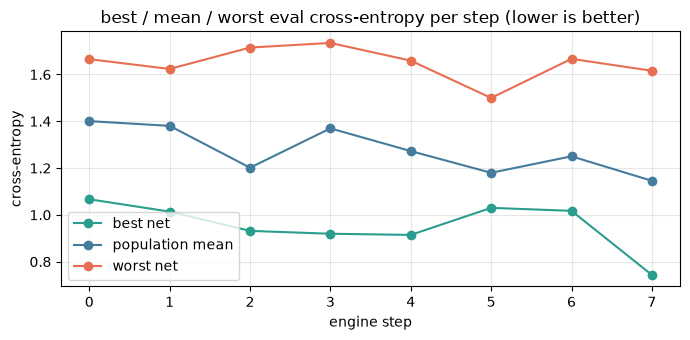

In [8]:
per_step = history.groupby("step")["fitness"].agg(["min", "mean", "max"])

ax = per_step.plot(marker="o", figsize=(7, 3.5),
                   color=["#2a9d8f", "#457b9d", "#e76f51"])
ax.set_title("best / mean / worst eval cross-entropy per step (lower is better)")
ax.set_xlabel("engine step")
ax.set_ylabel("cross-entropy")
ax.legend(["best net", "population mean", "worst net"])
ax.grid(alpha=0.3)
ax.figure.tight_layout();

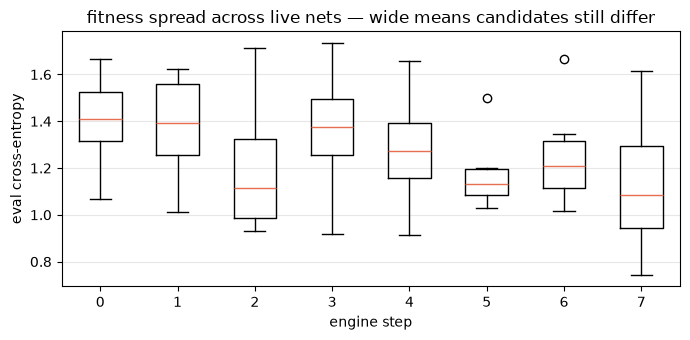

In [9]:
steps = sorted(history["step"].unique())
spread = [history.loc[history["step"] == step, "fitness"].to_numpy() for step in steps]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot(spread, widths=0.55, medianprops={"color": "#e76f51"})
ax.set_xticks(range(1, len(steps) + 1))
ax.set_xticklabels([str(step) for step in steps])
ax.set_title("fitness spread across live nets — wide means candidates still differ")
ax.set_xlabel("engine step")
ax.set_ylabel("eval cross-entropy")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout();

fitness == eval_loss in every row (the binding scores minimize(cross_entropy))


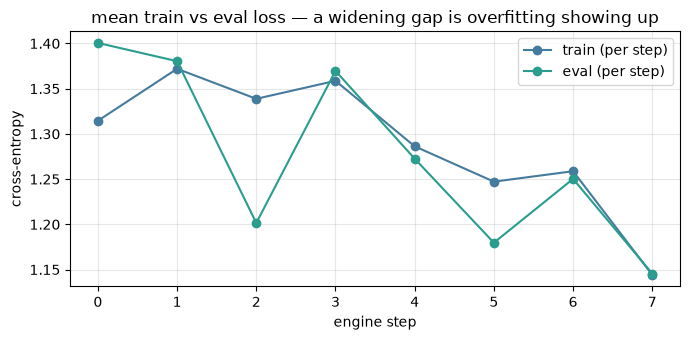

In [10]:
losses = history.groupby("step")[["train_loss", "eval_loss"]].mean()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(losses["train_loss"], marker="o", color="#457b9d", label="train (per step)")
ax.plot(losses["eval_loss"], marker="o", color="#2a9d8f", label="eval (per step)")
ax.set_title("mean train vs eval loss — a widening gap is overfitting showing up")
ax.set_xlabel("engine step")
ax.set_ylabel("cross-entropy")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

# In this binding fitness IS the eval loss, so the two columns agree by design.
assert (history["eval_loss"] - history["fitness"]).abs().max() < 1e-5
print("fitness == eval_loss in every row (the binding scores minimize(cross_entropy))")

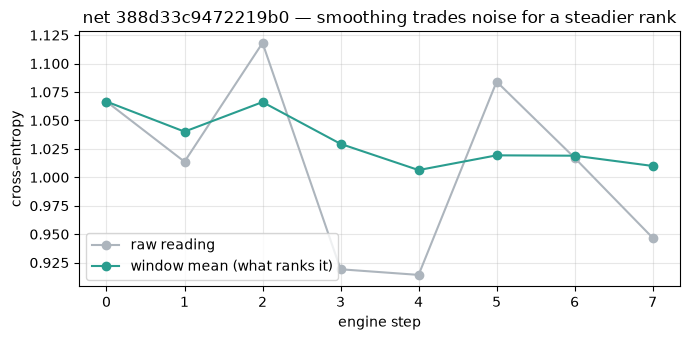

In [11]:
# One net's raw readings against the rolling value that actually ranks it.
busiest = history["hash"].value_counts().idxmax()
net_rows = history[history["hash"] == busiest].sort_values("step")

ax = net_rows.plot(x="step", y="fitness", marker="o", figsize=(7, 3.5),
                   color="#adb5bd", label="raw reading")
net_rows.plot(x="step", y="fitness_smooth", marker="o", ax=ax,
              color="#2a9d8f", label="window mean (what ranks it)")
ax.set_title(f"net {busiest} — smoothing trades noise for a steadier rank")
ax.set_xlabel("engine step")
ax.set_ylabel("cross-entropy")
ax.legend()
ax.grid(alpha=0.3)
ax.figure.tight_layout();

## 5. Determinism is the product

Same seed and config ⇒ the same `history.csv`, byte for byte. A different seed
⇒ a different stream. That is the whole promise, and it's the same guarantee
`python/tests/test_determinism.py` checks as a plain script.

**The header is the part people get wrong.** `engine.json` is a record of
*when*, not of *what*: its `run_id` is a millisecond stamp, and its timing
fields are wall-clock. Two identical races therefore differ in bytes there even
when every reading agrees — hash the stream, not the header.

In [12]:
def run_race(seed: int, *, risk_aversion: float = LAMBDA_OFF,
             pop: int = TINY_POP, steps: int = TINY_STEPS) -> tuple[Path, pd.DataFrame, dict]:
    """Run one race in a throwaway dir; nothing under results/ is touched."""
    run = Path(tempfile.mkdtemp(prefix=f"gras-seed{seed}-lam{risk_aversion}-"))
    config = RaceConfig(
        pop_size=pop,
        elite_count=ELITES,
        max_steps=steps,
        risk_aversion=risk_aversion,
        log_level="none",  # quiet: the CSV is the point here
    )
    race = RaceEngine(DATA_DIR, config, seed=seed, run_dir=run)
    assert race.run() == "MaxSteps"
    assert race.step_clock == steps
    history = pd.read_csv(run / "history.csv")
    header = json.loads((run / "engine.json").read_text())
    return run, history, header


def digest(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


run_a, history_a, header_a = run_race(SEED)
run_b, history_b, header_b = run_race(SEED)

print(f"history.csv  seed {SEED} → {digest(run_a / 'history.csv')}")
print(f"history.csv  seed {SEED} → {digest(run_b / 'history.csv')}  (rerun)")
print(f"engine.json  seed {SEED} → {digest(run_a / 'engine.json')}")
print(f"engine.json  seed {SEED} → {digest(run_b / 'engine.json')}  (rerun)")
print("\nheader keys that moved:", sorted(k for k in header_a if header_a[k] != header_b[k]))

assert digest(run_a / "history.csv") == digest(run_b / "history.csv")
assert history_a.equals(history_b)
assert digest(run_a / "engine.json") != digest(run_b / "engine.json")
print("replay holds: same stream, new header")

history.csv  seed 42 → efee1a0d90c3a6de23d3d0105be3c264c4be97e8447f6973efa9c8682b384c69
history.csv  seed 42 → efee1a0d90c3a6de23d3d0105be3c264c4be97e8447f6973efa9c8682b384c69  (rerun)
engine.json  seed 42 → 45bbfddad6bb24ecbdc36d07cdd5a2c823088ada3acab86c07f43475c611aaf4
engine.json  seed 42 → c22e73f26bc42ebbcf8387473fd21a48a6dc22eecd2007a7c4dfc3db01fc6d2e  (rerun)

header keys that moved: ['run_id']
replay holds: same stream, new header


## 6. `risk_aversion` as a before/after

λ only enters the **ranking**: the score is `window mean + λ × window spread`
(minimizing, so the charge hurts), and nothing else — no extra batch, no extra
forward pass. It decides which net loses its slot when evolution needs one.

**Before** — λ = 0: rank on the plain window mean.
**After** — λ = 2: the same race, same seed, with each net's own swing charged
against it.

The interesting half is what *doesn't* change: a net present in both runs reads
exactly the same numbers, because the stream never saw λ. What changes is who
survives — watch the first clock where the live sets part, then the chart, which
is the charge λ adds to those same means.

56 shared readings, 0 of them different
live sets first differ at step 5
  only in λ=0: ['2a8e6f9521e9c7dc']
  only in λ=2: ['5bec37ef83614191']


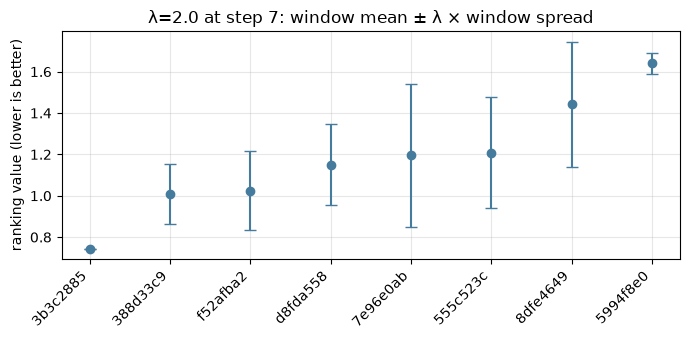

In [13]:
run_off, off, _ = run_race(SEED, risk_aversion=LAMBDA_OFF, pop=POP, steps=STEPS)
run_strict, strict, _ = run_race(SEED, risk_aversion=LAMBDA_STRICT, pop=POP, steps=STEPS)

# What λ cannot touch: a net alive in both runs reads identical numbers.
shared = off[["step", "hash", "fitness"]].merge(
    strict[["step", "hash", "fitness"]], on=["step", "hash"], suffixes=("_off", "_strict")
)
moved = (shared["fitness_off"] - shared["fitness_strict"]).abs() > 1e-9
print(f"{len(shared)} shared readings, {int(moved.sum())} of them different")

# What it does touch: the live set, from the first cull a charge can swing.
live_off = off.groupby("step")["hash"].agg(set)
live_strict = strict.groupby("step")["hash"].agg(set)
split = next((step for step in live_off.index if live_off[step] != live_strict[step]), None)
print(f"live sets first differ at step {split}")
if split is not None:
    print("  only in λ=0:", sorted(live_off[split] - live_strict[split]))
    print("  only in λ=2:", sorted(live_strict[split] - live_off[split]))

# The charge itself, at the last step: the same means, a higher rank value.
final_step = int(off["step"].max())
ranked = off[off["step"] == final_step].sort_values("fitness_smooth")
charge = LAMBDA_STRICT * ranked["fitness_smooth_std"]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(range(len(ranked)), ranked["fitness_smooth"], yerr=charge,
            fmt="o", capsize=4, color="#457b9d")
ax.set_xticks(range(len(ranked)))
ax.set_xticklabels(ranked["hash"].str[:8], rotation=45, ha="right")
ax.set_title(f"λ={LAMBDA_STRICT} at step {final_step}: window mean ± λ × window spread")
ax.set_ylabel("ranking value (lower is better)")
ax.grid(alpha=0.3)
fig.tight_layout();

## 7. Looking at a candidate

Each live net left a `nets/<hash>.json` last-state behind. It is an *envelope*:
race metadata on the outside, the architecture blueprint on the inside — and
the blueprint is stored as a JSON **string**, which is what the Rust side
persists. `Topology.from_json()` takes that inner string, so unwrap the
envelope first:

In [14]:
net_file = sorted((run_dir / "nets").glob("*.json"))[0]
envelope = json.loads(net_file.read_text())

print(f"{net_file.name}:")
print("  keys  :", sorted(envelope))
print(f"  from  : {envelope['created_from']}")
print(f"  alive : {envelope['is_alive']}  (culled at step {envelope['culled_at_step']})")
print(f"  params: {envelope['meta']['params']} across {envelope['meta']['param_tensors']} tensors")

2a8e6f9521e9c7dc.json:
  keys  : ['budget_skips', 'created_from', 'cull_reason', 'culled_at_step', 'elite_probation_age', 'elite_seat_age', 'entered_at_step', 'final_fitness_mean', 'final_fitness_samples', 'final_fitness_std', 'final_risk_score', 'frozen_spans', 'hash', 'idle_spans', 'is_alive', 'last_metrics', 'meta', 'net_seed', 'step', 'topology']
  from  : founder-2
  alive : False  (culled at step 6)
  params: 151 across 10 tensors


In [15]:
topology = Topology.from_json(envelope["topology"])
print(topology, "| nodes:", topology.node_count)

blueprint = json.loads(topology.to_json())
assert Topology.from_json(topology.to_json()).node_count == topology.node_count

print(f"graph: {len(blueprint['graph_inputs'])} open inputs → "
      f"{len(blueprint['graph_outputs'])} open outputs, "
      f"{len(blueprint['connections'])} wires")
for node in blueprint["nodes"]:
    print(f"  node {node['id']:>2}  {node['kind']:<7} "
          f"in={node['num_inputs']:<2} out={node['num_outputs']:<2} "
          f"dim={node['hidden_dim']:<3} act={node['activation']}")

Topology(nodes=4) | nodes: 4
graph: 5 open inputs → 12 open outputs, 5 wires
  node  0  Input   in=0  out=2  dim=8   act=Identity
  node  1  Hidden  in=1  out=2  dim=4   act=GeLU
  node  2  Hidden  in=2  out=1  dim=4   act=LogSoftmax
  node  3  Output  in=2  out=1  dim=3   act=Identity


What that blueprint is *not*: weights. `gras` never serializes them as the
source of truth — a net is reproduced by replaying its seed and step
(`engine.json` + `nets/`). The one exception is deliberate: an elite may also
leave an `elite-<hash>.safetensors` snapshot, which is a copy for inspection,
not the thing a resume trusts.

## 8. Bringing your own data

`RaceEngine` takes a **directory**, not arrays. Two layouts are accepted:

| files | who writes them | notes |
|---|---|---|
| `inputs.bin` + `targets.bin` | the crate (`save_dataset`) | native: `GRA1` magic, 1-byte dtype tag, `u64` ndim + dims, then the tensor bytes |
| `inputs.csv` + `targets.csv` | you | comma-separated floats, header optional, `#` lines skipped; converted once and cached under `<dir>/flodl_data/` |

Or skip the directory as an *input*: `RaceEngine.from_arrays(X, Y, dir, cfg)` writes
that native pair straight from NumPy (`float32`/`float64` only) and then behaves
exactly like the directory form — same files, so a resume reads what a previous run
wrote.

The recipe is defaulted, not fixed — `loss=` picks it at construction (see
`gras.losses()`), and the default is one-hot cross-entropy:

- **one-hot targets by default** (`dim = number of classes`), because the
  default loss scores `cross_entropy`. A single label column needs a loss that
  expects one — `mse`, `l1` or `bce_with_logits` — not the default.
- **no train/eval split to manage**: `input_dim` / `output_dim` are read from the
  data, and the engine's seeded stream owns the split. That is why the run is
  replayable without you shipping an index file.

The next two cells race two very different directories with the same three
lines: a 64-row toy set built here with NumPy, and the real MNIST checkout
(`data/mnist/train`). Nothing about the call changes.

In [ ]:
# Your own data: two CSVs, one row per sample, one-hot targets.
rng = np.random.default_rng(0)
samples, features, classes = 64, 2, 3
X = rng.normal(size=(samples, features)).astype(np.float32)
label = ((X[:, 0] + 0.5 * X[:, 1]) > 0).astype(int) + (X[:, 1] > 0.5).astype(int)
Y = np.eye(classes, dtype=np.float32)[label]

data_dir = Path(tempfile.mkdtemp(prefix="gras-own-data-"))
np.savetxt(data_dir / "inputs.csv", X, delimiter=",")
np.savetxt(data_dir / "targets.csv", Y, delimiter=",")
print("wrote:", sorted(p.name for p in data_dir.iterdir()))

own = RaceEngine(
    data_dir,
    RaceConfig(pop_size=4, elite_count=1, max_steps=3, log_level="none"),
    seed=SEED,
    run_dir=Path(tempfile.mkdtemp(prefix="gras-own-run-")),
)
print(f"stop: {own.run()} after {own.step_clock} steps")
own_history = pd.read_csv(Path(own.run_dir) / "history.csv")
print(f"{len(own_history)} readings, best fitness {own_history['fitness'].min():.3f}")
print("the engine cached its binary copy:", sorted(p.name for p in data_dir.iterdir()))

### The same call on MNIST

`data/mnist/train` is `60000 × 784` inputs and `60000 × 10` one-hot targets, in
the native layout. A step draws `batch_size = 16` train rows and 16 eval rows
from the seeded stream, so cost is per **batch**, not per dataset: this whole
2-step race takes under a second despite the 60k rows. `eval_loss` near
`ln(10) ≈ 2.303` means "no idea yet" — useful ballast when reading the charts.

In [ ]:
# Same call, unchanged — only the directory differs.
mnist = RaceEngine(
    REPO_ROOT / "data/mnist/train",
    RaceConfig(pop_size=4, elite_count=1, max_steps=2, log_level="none"),
    seed=SEED,
    run_dir=Path(tempfile.mkdtemp(prefix="gras-mnist-run-")),
)
print(f"stop: {mnist.run()} after {mnist.step_clock} steps")
mnist_history = pd.read_csv(Path(mnist.run_dir) / "history.csv")
mnist_header = json.loads((Path(mnist.run_dir) / "engine.json").read_text())
print(f"dims read from the data: {mnist_header['input_dim']} -> {mnist_header['output_dim']}")
print(
    f"best eval_loss {mnist_history['eval_loss'].min():.3f}"
    f" (ln 10 = {np.log(10):.3f} is 'no idea yet')"
)

## 9. The other arm: an environment instead of a dataset

`RaceEngine.gym(env, cfg)` takes anything with gym's shape — `reset(seed=…)`,
`step(action)` returning a 5-tuple, a discrete `action_space.n`, and
`spec.max_episode_steps` — and races the crate's `Reinforce` over it. Nothing
about CartPole is compiled in: the world is yours, the algorithm is the crate's,
and the seed is always passed to `reset`, which is what keeps the stream
reproducible.

The artifacts are the same files as always; `engine.json` records
`engine_mode: "rl"` plus the env's shape (`env`, `actions`, `max_turns`).


In [ ]:
# The other arm — same RaceConfig, same seed ⇒ same-stream promise. The demo
# world is the only thing that changes: `algo=`, `discount=` and `challenge_prob=`
# are the rest of the surface (`gras.algos()` lists the first).
try:
    import gymnasium
except ImportError:  # the tour stays runnable without it
    gymnasium = None
    print("gymnasium not installed - `pip install gymnasium` to run this cell")

if gymnasium is not None:
    rl = RaceEngine.gym(
        gymnasium.make("CartPole-v1"),
        RaceConfig(pop_size=4, elite_count=1, max_steps=2, log_level="none"),
        seed=SEED,
        run_dir=Path(tempfile.mkdtemp(prefix="gras-notebook-rl-")),
        lr=1e-3,
    )
    header = json.loads((Path(rl.run_dir) / "engine.json").read_text())
    print(rl.run(), "|", header["engine_mode"], "|", header["trainer"]["env"]["env"])



## 10. What v1 deliberately does not do

- **No Python inside a step.** The trainer is the crate's `TabularTrainer`,
  selected by NAME here (`loss=`, `fitness=`, `metrics=`, `lr=`) — no callback,
  loss function or fitness function crosses the boundary, so the recipe a run
  records is the one Rust would run. That is what keeps it replayable.
- **No per-step control.** `run()` is whole-race and holds the GIL while it
  works: the engine is `!Send` (libtorch tensors are `Rc<RefCell<_>>`), so one
  Python thread cannot step a race while another thread does something else.
- **No NumPy views or `Network` / `Fitness` objects.** Topology in, JSON out;
  the artifacts stay the interface.
- **No inheritance by default.** `elite_previous_load=False` means a Python run
  never silently seeds itself from whatever sits in your `results/`.
- **Discrete action spaces only.** `RaceEngine.gym` drives the crate's
  `Reinforce`, so an environment needs a discrete `action_space.n`; a `Box`
  space needs a different policy head and a different objective, which is a
  decision, not a flag — so it is refused by name.
- **No feature engineering.** You supply the numbers — a directory of CSVs or
  `from_arrays` — and the engine converts, caches and splits, but it will not
  reshape or normalise your features for you.

## Where to go next

- `python/tests/test_determinism.py` — the replay guarantee as a plain script:

  ```bash
  source env_setup.sh && .venv/bin/python python/tests/test_determinism.py
  ```
- `notes/PYTHON_BINDINGS.md` — the "why" companion: PyO3, `cdylib`, maturin, a
  tour of `gras-py/src/lib.rs`, and what the wrapping costs.
- `TODO.md` → *Priority 1 — Python bindings* — the open work (per-step control,
  releasing the GIL, Python callbacks, a distributable wheel).